In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [14]:
import os

folder = r"C:\Users\saite\cynaris-internship-saikrishna\week-2\W2D6_Data_Governance"

print(os.listdir(folder))

['contracts', 'data', 'indian_business_dataset.csv', 'reports']


In [15]:
import os

folder = r"C:\Users\saite\cynaris-internship-saikrishna\week-2\W2D6_Data_Governance"

for file in os.listdir(folder):
    print(file)

contracts
data
indian_business_dataset.csv
reports


In [16]:
import pandas as pd

file_path = r"C:\Users\saite\cynaris-internship-saikrishna\week-2\W2D6_Data_Governance\indian_business_dataset.csv"

df = pd.read_csv(file_path)

print(df.head())

  business_id     business_name    owner_name           state       city  age  \
0        B001       Sri Traders    Ravi Kumar  Andhra Pradesh   Tirupati   35   
1        B002        ABC Stores     Anita Rao       Telangana  Hyderabad   42   
2        B003  Lakshmi Textiles  Lakshmi Devi       Karnataka  Bengaluru   29   
3        B004        Green Mart  Suresh Reddy      Tamil Nadu    Chennai   51   
4        B005  Ravi Enterprises  Priya Sharma     Maharashtra       Pune   38   

                email       phone  annual_revenue            gstin  
0  owner1@example.com  9000000001          500000  37ABCDE0001F1Z5  
1  owner2@example.com  9000000002          750000  37ABCDE0002F1Z5  
2  owner3@example.com  9000000003          420000  37ABCDE0003F1Z5  
3  owner4@example.com  9000000004          900000  37ABCDE0004F1Z5  
4                 NaN  9000000005          650000  37ABCDE0005F1Z5  


In [17]:
print("Rows and columns:", df.shape)

Rows and columns: (50, 10)


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   business_id     50 non-null     str  
 1   business_name   50 non-null     str  
 2   owner_name      50 non-null     str  
 3   state           50 non-null     str  
 4   city            50 non-null     str  
 5   age             50 non-null     int64
 6   email           49 non-null     str  
 7   phone           50 non-null     int64
 8   annual_revenue  50 non-null     int64
 9   gstin           50 non-null     str  
dtypes: int64(3), str(7)
memory usage: 4.0 KB


In [20]:
missing_values = df.isnull().sum()

print(missing_values)

business_id       0
business_name     0
owner_name        0
state             0
city              0
age               0
email             1
phone             0
annual_revenue    0
gstin             0
dtype: int64


In [21]:
print(df[df['email'].isnull()])

  business_id     business_name    owner_name        state  city  age email  \
4        B005  Ravi Enterprises  Priya Sharma  Maharashtra  Pune   38   NaN   

        phone  annual_revenue            gstin  
4  9000000005          650000  37ABCDE0005F1Z5  


In [23]:
df['email'] = df['email'].fillna('Not Provided')

In [24]:
print(df.isnull().sum())

business_id       0
business_name     0
owner_name        0
state             0
city              0
age               0
email             0
phone             0
annual_revenue    0
gstin             0
dtype: int64


In [25]:
duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)

Total duplicate rows: 0


In [26]:
df.describe()

,age,phone,annual_revenue
count,50.000000,5.000000e+01,50.000000
mean,40.820000,9.000000e+09,629000.000000
std,17.305998,1.457738e+01,162722.375316
min,27.000000,9.000000e+09,380000.000000
25%,33.000000,9.000000e+09,500000.000000
50%,39.000000,9.000000e+09,625000.000000
75%,44.000000,9.000000e+09,750000.000000
max,150.000000,9.000000e+09,900000.000000


In [27]:
state_counts = df['state'].value_counts()

print(state_counts)

state
Andhra Pradesh    10
Telangana         10
Karnataka         10
Tamil Nadu        10
Maharashtra       10
Name: count, dtype: int64


In [28]:
city_counts = df['city'].value_counts()

print(city_counts)

city
Tirupati     10
Hyderabad    10
Bengaluru    10
Chennai      10
Pune         10
Name: count, dtype: int64


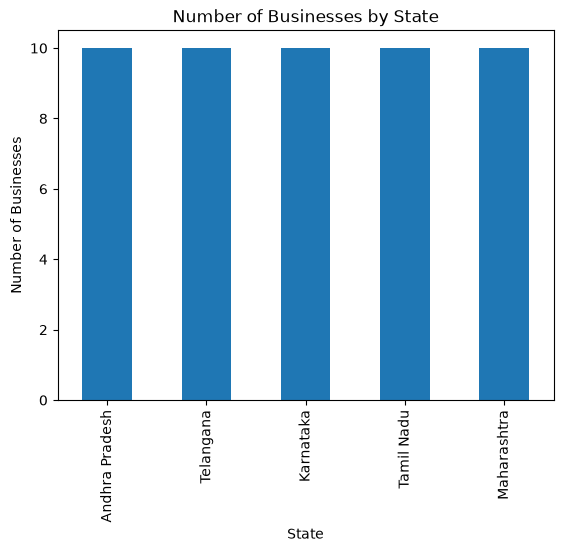

In [29]:
import matplotlib.pyplot as plt

state_counts = df['state'].value_counts()

state_counts.plot(kind='bar')

plt.title('Number of Businesses by State')
plt.xlabel('State')
plt.ylabel('Number of Businesses')

plt.show()

In [30]:
highest_revenue = df['annual_revenue'].max()

print("Highest Annual Revenue:", highest_revenue)

Highest Annual Revenue: 900000


In [31]:
top_business = df.loc[df['annual_revenue'].idxmax()]

print(top_business)

business_id                     B004
business_name             Green Mart
owner_name              Suresh Reddy
state                     Tamil Nadu
city                         Chennai
age                               51
email             owner4@example.com
phone                     9000000004
annual_revenue                900000
gstin                37ABCDE0004F1Z5
Name: 3, dtype: object


In [32]:
average_revenue = df['annual_revenue'].mean()

print("Average Annual Revenue:", average_revenue)

Average Annual Revenue: 629000.0


In [33]:
lowest_revenue = df['annual_revenue'].min()

print("Lowest Annual Revenue:", lowest_revenue)

Lowest Annual Revenue: 380000


In [34]:
state_revenue = df.groupby('state')['annual_revenue'].sum()

print(state_revenue)

state
Andhra Pradesh    6600000
Karnataka         4000000
Maharashtra       6250000
Tamil Nadu        8050000
Telangana         6550000
Name: annual_revenue, dtype: int64


In [35]:
average_state_revenue = df.groupby('state')['annual_revenue'].mean()

print(average_state_revenue)

state
Andhra Pradesh    660000.0
Karnataka         400000.0
Maharashtra       625000.0
Tamil Nadu        805000.0
Telangana         655000.0
Name: annual_revenue, dtype: float64


In [36]:
top_state = state_revenue.idxmax()

print("Top Revenue State:", top_state)

Top Revenue State: Tamil Nadu


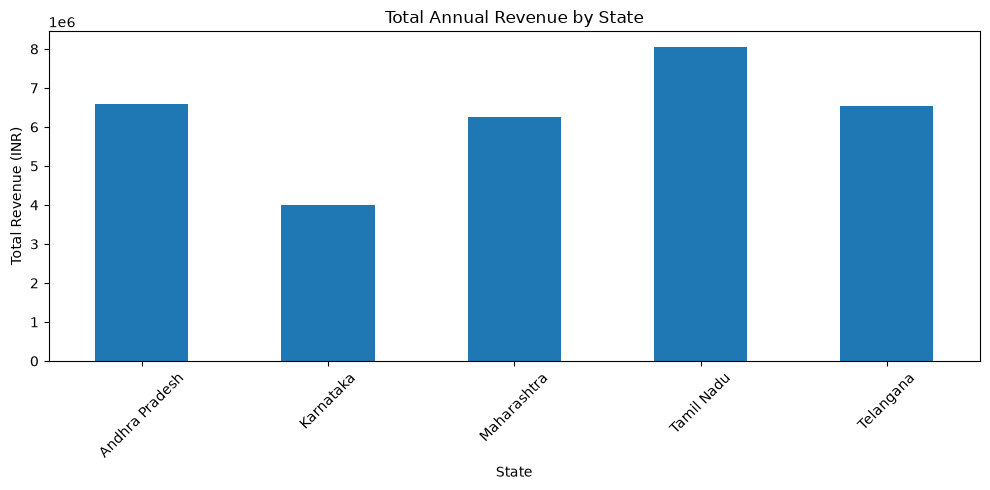

In [37]:
import matplotlib.pyplot as plt

state_revenue = df.groupby('state')['annual_revenue'].sum()

state_revenue.plot(kind='bar', figsize=(10, 5))

plt.title('Total Annual Revenue by State')
plt.xlabel('State')
plt.ylabel('Total Revenue (INR)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
average = df['annual_revenue'].mean()
print("Average Revenue:", average)
median = df['annual_revenue'].median()
print("Median Revenue:", median)
std = df['annual_revenue'].std()
print("Revenue Standard Deviation:", std)

Average Revenue: 629000.0
Median Revenue: 625000.0
Revenue Standard Deviation: 162722.37531627735


In [41]:
correlation = df['age'].corr(df['annual_revenue'])

print("Age and Revenue Correlation:", correlation)

Age and Revenue Correlation: 0.21980964055613708


In [42]:
df.to_csv(
    'indian_business_cleaned.csv',
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [43]:
import os

print(os.getcwd())
print(os.path.exists('indian_business_cleaned.csv'))

c:\Users\saite\cynaris-internship-saikrishna\week-4
True


In [44]:
import os

print(os.getcwd())

c:\Users\saite\cynaris-internship-saikrishna\week-4


In [45]:
print(os.listdir())


['cap_stone.ipynb', 'hypothesis_tests.ipynb', 'indian_business_cleaned.csv', 'probability.ipynb', 'regression_analysis.ipynb', 'statistics_analysis.ipynb']


In [46]:
output_path = r"C:\Users\saite\cynaris-internship-saikrishna\week-2\W2D6_Data_Governance\indian_business_cleaned.csv"

df.to_csv(output_path, index=False)

print("CSV file saved!")

CSV file saved!


In [47]:
import os

print(os.path.exists(output_path))

True


In [4]:
import pandas as pd

file_path = r"C:\Users\saite\cynaris-internship-saikrishna\week-2\W2D6_Data_Governance\indian_business_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(50, 10)


In [5]:

# 1. Total number of businesses
total_businesses = len(df)

# 2. Total annual revenue
total_revenue = df['annual_revenue'].sum()

# 3. State with highest total revenue
state_revenue = df.groupby('state')['annual_revenue'].sum()
highest_revenue_state = state_revenue.idxmax()
highest_revenue = state_revenue.max()

# 4. City with the most businesses
city_counts = df['city'].value_counts()
highest_business_city = city_counts.idxmax()
highest_city_count = city_counts.max()

# 5. Average annual revenue
average_revenue = df['annual_revenue'].mean()

# Display results
print("INDIAN BUSINESS ANALYSIS")
print("------------------------")

print("Total Businesses:", total_businesses)

print("Total Annual Revenue: ₹", total_revenue)

print("Highest Revenue State:", highest_revenue_state)

print("Revenue of Highest State: ₹", highest_revenue)

print("City with Most Businesses:", highest_business_city)

print("Businesses in That City:", highest_city_count)

print("Average Annual Revenue: ₹", round(average_revenue, 2))


INDIAN BUSINESS ANALYSIS
------------------------
Total Businesses: 50
Total Annual Revenue: ₹ 31450000
Highest Revenue State: Tamil Nadu
Revenue of Highest State: ₹ 8050000
City with Most Businesses: Tirupati
Businesses in That City: 10
Average Annual Revenue: ₹ 629000.0
